# Maternal health-seeking behaviour (EDHS 2024/25): revised analysis
Google Colab notebook for the revision of *Understanding Maternal Health-Seeking Behaviour: A Comparative Machine Learning Analysis of Socio-Economic and Demographic Factors*.

**What it does:** builds the cohort and composite outcome (>=2 of 4 components), then runs nested, cluster-grouped cross-validation for 8 models, bootstrap CIs, calibration, thresholds, decision curves, permutation importance, sensitivity analyses and partial dependence. An optional last section adds LightGBM/XGBoost and SHAP.

**Unit of analysis:** the data file is a *pregnancy-level* recode (8,615 rows from 7,379 women). The analysis uses one record per woman: her most recent live birth in the 5 years before the survey (`midx == 1`), with complete data on all four outcome components (n = 6,658).

**How to run:** `Runtime > Run all`. Google Drive is mounted automatically (allow access when prompted) and the data are read from `/content/drive/MyDrive/DHIS/datas_2.csv`. Section 3 (nested CV) takes about 10-20 minutes on a free Colab CPU. Every table is printed in the notebook and every figure is displayed inline; CSV tables and PNG figures are also saved to `/content/drive/MyDrive/DHIS/results/` and zipped in the last cell.

Notes: variable labels were checked against the EDHS 2024/25 recode codebook (ETGR8AFL.DO). The optional LightGBM/SHAP section has not been tested.

## 0. Setup and data

In [1]:
import os, warnings, pickle, time
warnings.filterwarnings('ignore')
from google.colab import drive, files
from IPython.display import display
%matplotlib inline

# ---- Mount Google Drive ----
drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/DHIS/datas_2.csv'
OUT_DIR   = '/content/drive/MyDrive/DHIS/results'     # all tables/figures are saved here
os.makedirs(OUT_DIR, exist_ok=True)
os.environ['DATA_PATH'] = DATA_PATH
assert os.path.exists(DATA_PATH), f'Data file not found: {DATA_PATH}'
os.chdir(OUT_DIR)                                      # outputs (csv, png, pkl) are written to OUT_DIR

import pandas as pd
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 500); pd.set_option('display.float_format', lambda v: f'{v:.3f}')
print('Data path  :', DATA_PATH)
print('Output dir :', OUT_DIR)


Mounted at /content/drive
Data path  : /content/drive/MyDrive/DHIS/datas_2.csv
Output dir : /content/drive/MyDrive/DHIS/results


## 1. Cohort and outcome
One row per woman (most recent live birth, `midx == 1`); 'don't know' codes set to missing; facility = government, private or NGO facility. Outcome: good = score >= 2 of 4 (>=4 ANC visits, facility delivery, first ANC within 3 months, >=2 tetanus injections).

In [2]:
import pandas as pd, numpy as np
FAC=[21,22,23,26,31,32,36,41,46]   # public, private and NGO health facility codes (m15)
import os
def build(path=DATA_PATH):
    df=pd.read_csv(path,low_memory=False)
    n0=len(df)
    anc=df.m14.where(df.m14<90)                        # 98 = don't know -> missing
    place=df.m15.where(~df.m15.isin([96,99]))          # 96 other, 99 missing -> missing
    early=df.m13.where(df.m13<90)
    tt=df.m1.where(df.m1!=8)                           # 8 = don't know -> missing
    c_anc4=(anc>=4).astype(float).where(anc.notna())
    c_fac=place.isin(FAC).astype(float).where(place.notna())
    # early ANC: undefined if no ANC info; 'no' if no ANC at all
    c_early=pd.Series(np.where(anc==0,0.0,np.where(early.notna(),(early<=3).astype(float),np.nan)),index=df.index)
    c_tt=(tt>=2).astype(float).where(tt.notna())
    comp=pd.DataFrame({'anc4':c_anc4,'facility':c_fac,'early_anc':c_early,'tt2':c_tt})
    # The file is a pregnancy-level recode: one row per pregnancy (pidx) with midx = index to birth history.
    # Unit of analysis = woman, using her MOST RECENT live birth in the 5 years before the survey (midx == 1).
    flow={'pregnancy records in file':n0, 'women (unique caseid)':int(df.caseid.nunique())}
    recent=(df.midx==1)
    flow['women with a live birth in the reference period (midx==1)']=int(recent.sum())
    complete=comp.notna().all(axis=1) & recent
    flow['complete data on all four components']=int(complete.sum())
    d=df[complete].copy(); comp=comp[complete]
    d['score']=comp.sum(axis=1); d['y']=(d.score>=2).astype(int)
    for c in comp: d['c_'+c]=comp[c]
    return df,d,flow

df_all, d_chk, flow_chk = build(); print('Cohort flow:'); display(pd.DataFrame({'Step':list(flow_chk), 'n':list(flow_chk.values())}))
print('Prevalence of good:', round(d_chk.y.mean(), 3))

Cohort flow:


,Step,n
0,pregnancy records in file,8615
1,women (unique caseid),7379
2,women with a live birth in the reference perio...,6940
3,complete data on all four components,6658


Prevalence of good: 0.557


## 2. Predictors and preprocessing pipeline
Special codes recoded to missing; nominal variables one-hot encoded; sampling weight NOT a predictor; all preprocessing sits inside the model pipeline.

In [3]:
import numpy as np, pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer

# ---- cleaning of DHS special codes (all done BEFORE modelling, no information from outcome used) ----
def prepare():
    df, d, flow = build()
    X = pd.DataFrame(index=d.index)
    X['age']            = d.v012
    X['parity']         = d.v201
    X['living_children']= d.v218
    X['age_first_birth']= d.v212.where(d.v212 < 90)
    X['marr_to_birth_months'] = d.v221.where((d.v221 >= 0) & (d.v221 < 900))   # 996 = not applicable/inconsistent
    X['partner_age']    = d.v730.where(d.v730 < 90)
    X['partner_educ_years'] = d.v715.where(d.v715 < 90)                         # 98 = don't know
    # ordinal / binary (treated as numeric)
    X['educ_level']     = d.v106
    X['wealth_quintile']= d.v190
    for c, n in [('v119','electricity'),('v120','radio'),('v121','television'),('v122','refrigerator'),
                 ('v123','bicycle'),('v124','motorcycle'),('v125','car_truck'),('v153','telephone')]:
        X[n] = d[c].where(d[c] != 7)                                             # 7 = not de jure resident
    X['news_freq']      = d.v157
    X['radio_freq']     = d.v158
    X['tv_freq']        = d.v159
    X['currently_pregnant'] = d.v213
    X['respondent_working'] = d.v714
    # nominal -> categorical
    cats = {'residence':'v025','region':'v024','marital_status':'v501','contraceptive_method':'v312',
            'literacy':'v155','decide_own_health':'v743a','decide_purchases':'v743b',
            'owns_house':'v745a','owns_land':'v745b','partner_educ_level':'v701',
            'partner_occupation':'v704','partner_educ_highest':'v729'}
    for n, c in cats.items():
        s = d[c].copy()
        if n == 'partner_occupation': s = s.where(s < 99990)
        if n in ('partner_educ_level','partner_educ_highest'): s = s.where(s != 8)
        X[n] = np.where(s.notna(), s.round().astype('Int64').astype(str), 'missing')
    cat_cols = list(cats)
    cont_cols = ['age','parity','living_children','age_first_birth','marr_to_birth_months','partner_age','partner_educ_years']
    ord_cols = [c for c in X.columns if c not in cat_cols + cont_cols]
    meta = pd.DataFrame({'psu': d.v021, 'strata': d.v022, 'wt': d.v005/1e6})
    return d, X, d.y.values, meta, flow, dict(cat=cat_cols, cont=cont_cols, ord=ord_cols)

def make_pre(cols, spline=False):
    cont = [c for c in cols['cont']]; ordc = cols['ord']; cat = cols['cat']
    if spline:
        cont_t = Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                           ('spl', SplineTransformer(n_knots=5, degree=3, include_bias=False))])
    else:
        cont_t = Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())])
    ord_t = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())])
    cat_t = Pipeline([('oh', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=False))])
    return ColumnTransformer([('cont', cont_t, cont), ('ord', ord_t, ordc), ('cat', cat_t, cat)], remainder='drop')

## 2b. Descriptive tables (Tables 1-3, outcome components, included vs excluded)

In [4]:
import os, numpy as np, pandas as pd
d, X, y, meta, flow, cols = prepare()
REG={1:'Tigray',2:'Afar',3:'Amhara',4:'Oromia',5:'Somali',6:'Benishangul-Gumuz',7:'Central Ethiopia',8:'Sidama',9:'South West Ethiopia',10:'South Ethiopia',12:'Gambella',13:'Harari',14:'Addis Ababa',15:'Dire Dawa'}
EDU={0:'No education',1:'Primary',2:'Secondary',3:'Higher'}
WEA={1:'Poorest',2:'Poorer',3:'Middle',4:'Richer',5:'Richest'}
LIT={0:'Cannot read at all',1:'Able to read only parts',2:'Able to read whole sentence',3:'No card with required language',4:'Blind/visually impaired'}
RES={1:'Urban',2:'Rural'}
MAR={0:'Never married',1:'Married',2:'Living with partner',3:'Widowed',4:'Divorced',5:'Separated'}
rows=[]
n=len(d)
def cat(label,s,mp):
    vc=s.value_counts()
    for k,v in mp.items():
        c=int(vc.get(k,0));
        # outcome prevalence within category
        py=d.y[s==k].mean()*100 if c>0 else np.nan
        rows.append((label,v,f'{c:,} ({c/n*100:.1f}%)',f'{py:.1f}%'))
rows.append(('Sample size','',f'{n:,}',f'{d.y.mean()*100:.1f}%'))
rows.append(('Age (years)','mean (SD)',f'{d.v012.mean():.1f} ({d.v012.std():.1f})',''))
bins=[14,19,24,29,34,39,44,49]; lab=['15–19','20–24','25–29','30–34','35–39','40–44','45–49']
ag=pd.cut(d.v012,bins=bins,labels=lab)
for l in lab:
    c=int((ag==l).sum()); rows.append(('Age group',l,f'{c:,} ({c/n*100:.1f}%)',f'{d.y[ag==l].mean()*100:.1f}%'))
cat('Region',d.v024,REG); cat('Residence',d.v025,RES); cat('Education',d.v106,EDU); cat('Wealth quintile',d.v190,WEA); cat('Literacy',d.v155,LIT); cat('Marital status',d.v501,MAR)
t1=pd.DataFrame(rows,columns=['Variable','Category','n (%) / statistic','Good health-seeking, % of row'])
t1.to_csv('table1.csv',index=False)
# Table 2 reproductive/partner
r2=[]
def ms(label,s,med=True):
    s=s.dropna()
    r2.append((label,f'{s.mean():.2f} ({s.std():.2f})',f'{s.median():.1f} ({s.quantile(.25):.1f}–{s.quantile(.75):.1f})',f'{len(s):,}'))
ms('Total children ever born',d.v201); ms('Living children',d.v218)
ms('Age at first birth (years)',X.age_first_birth)
ms('Marriage-to-first-birth interval (months)*',X.marr_to_birth_months)
ms('Partner age (years)',X.partner_age); ms('Partner education (years)**',X.partner_educ_years)
t2=pd.DataFrame(r2,columns=['Variable','Mean (SD)','Median (IQR)','n with valid data']); t2.to_csv('table2.csv',index=False)
cm={0:'Not using',1:'Pill',2:'IUD',3:'Injectables',5:'Male condom',6:'Female sterilisation',8:'Periodic abstinence',9:'Withdrawal',11:'Implants',13:'Lactational amenorrhoea',16:'Emergency/other',18:'Standard days method'}
r3=[]
vc=d.v312.value_counts()
for k,v in vc.items(): r3.append(('Current contraceptive method',cm.get(k,f'code {k}'),f'{v:,} ({v/n*100:.1f}%)'))
r3.append(('Currently pregnant','Yes',f'{int(d.v213.sum()):,} ({d.v213.mean()*100:.1f}%)'))
pd.DataFrame(r3,columns=['Variable','Category','n (%)']).to_csv('table2b.csv',index=False)
# outcome components
comp=pd.DataFrame({'Component':['≥4 antenatal care visits','Delivery in a health facility','First antenatal visit within 3 months of pregnancy','≥2 tetanus toxoid injections during pregnancy'],
  'n (%) meeting':[f'{int(d[c].sum()):,} ({d[c].mean()*100:.1f}%)' for c in ['c_anc4','c_facility','c_early_anc','c_tt2']]})
comp.to_csv('components.csv',index=False)
sc=d.score.value_counts().sort_index(); pd.DataFrame({'Score':sc.index.astype(int),'n':sc.values,'%':(sc.values/n*100).round(1)}).to_csv('score_dist.csv',index=False)
# weighted prevalence
w=meta.wt.values; print('weighted prevalence good:', np.average(d.y,weights=w).round(3), 'unweighted', d.y.mean().round(3))
# included vs excluded among women with birth records
dfall=pd.read_csv(DATA_PATH,low_memory=False)
hb=(dfall.midx==1)
inc=dfall.index.isin(d.index)
ex=hb & ~inc
cmpr=[]
for lab,s in [('Age, mean',dfall.v012),('Rural residence, %',(dfall.v025==2)*100),('No education, %',(dfall.v106==0)*100),('Poorest/poorer wealth, %',dfall.v190.isin([1,2])*100),('Children ever born, mean',dfall.v201)]:
    cmpr.append((lab,f'{s[inc].mean():.1f}',f'{s[ex].mean():.1f}'))
pd.DataFrame(cmpr,columns=['Characteristic','Analytic sample (n=%d)'%inc.sum(),'Women with a recent live birth excluded for incomplete outcome data (n=%d)'%ex.sum()]).to_csv('excluded_compare.csv',index=False)
print(flow, inc.sum(), ex.sum())
print('\nTable 1. Sociodemographic characteristics and outcome prevalence'); display(t1)
print('\nTable 2. Reproductive and partner characteristics'); display(t2)
print('\nTable 2b. Contraceptive method and current pregnancy'); display(pd.read_csv('table2b.csv'))
print('\nOutcome components'); display(comp)
print('\nComposite score distribution'); display(pd.read_csv('score_dist.csv'))
print('\nIncluded vs excluded women'); display(pd.read_csv('excluded_compare.csv'))
print('\nMissing by component among women with birth records:')
sub=dfall[hb]
print('among most-recent-birth records: m14 NaN/DK',(sub.m14.isna()|(sub.m14>=90)).sum(),'m15 NaN/other',(sub.m15.isna()|sub.m15.isin([96,99])).sum(),'m1 NaN/DK',(sub.m1.isna()|(sub.m1==8)).sum(),'m13 DK',(sub.m13>=90).sum())


weighted prevalence good: 0.614 unweighted 0.557
{'pregnancy records in file': 8615, 'women (unique caseid)': 7379, 'women with a live birth in the reference period (midx==1)': 6940, 'complete data on all four components': 6658} 6658 282

Table 1. Sociodemographic characteristics and outcome prevalence


,Variable,Category,n (%) / statistic,"Good health-seeking, % of row"
0,Sample size,,"6,658",55.7%
1,Age (years),mean (SD),29.1 (6.5),
2,Age group,15–19,340 (5.1%),51.8%
3,Age group,20–24,"1,374 (20.6%)",56.6%
4,Age group,25–29,"2,087 (31.3%)",58.4%
5,Age group,30–34,"1,387 (20.8%)",57.2%
6,Age group,35–39,"1,013 (15.2%)",53.2%
7,Age group,40–44,348 (5.2%),48.3%
8,Age group,45–49,109 (1.6%),33.9%
9,Region,Tigray,589 (8.8%),57.0%



Table 2. Reproductive and partner characteristics


,Variable,Mean (SD),Median (IQR),n with valid data
0,Total children ever born,3.57 (2.35),3.0 (2.0–5.0),"6,658"
1,Living children,3.36 (2.19),3.0 (2.0–5.0),"6,658"
2,Age at first birth (years),20.12 (4.04),20.0 (17.0–22.0),"6,658"
3,Marriage-to-first-birth interval (months)*,28.16 (25.16),21.0 (12.0–34.0),"6,237"
4,Partner age (years),36.55 (9.05),35.0 (30.0–41.0),"6,264"
5,Partner education (years)**,5.79 (5.46),5.0 (0.0–10.0),"6,183"



Table 2b. Contraceptive method and current pregnancy


...


Composite score distribution


,Score,n,%
0,0,1799,27.000
1,1,1151,17.300
2,2,1349,20.300
3,3,1376,20.700
4,4,983,14.800



Included vs excluded women


,Characteristic,Analytic sample (n=6658),Women with a recent live birth excluded for incomplete outcome data (n=282)
0,"Age, mean",29.100,29.900
1,"Rural residence, %",70.700,72.000
2,"No education, %",40.100,43.300
3,"Poorest/poorer wealth, %",53.500,51.800
4,"Children ever born, mean",3.600,3.800



Missing by component among women with birth records:
among most-recent-birth records: m14 NaN/DK 23 m15 NaN/other 54 m1 NaN/DK 195 m13 DK 16


## 3. Nested, cluster-grouped cross-validation (8 models)
Outer 5-fold; inner 3-fold grid search on AUC; folds grouped by sampling cluster. ~10-20 min.

In [5]:
import numpy as np, pandas as pd, pickle, time, warnings, sys
warnings.filterwarnings('ignore')
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

d, X, y, meta, flow, cols = prepare()
groups = meta.psu.values
SEED = 2026
def spec():
    return {
     'Logistic regression':      (lambda: LogisticRegression(max_iter=3000), {'m__C':[0.01,0.1,1,10]}, False),
     'Logistic regression (splines)': (lambda: LogisticRegression(max_iter=3000), {'m__C':[0.01,0.1,1]}, True),
     'Random forest':            (lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1), {'m__max_depth':[6,12],'m__min_samples_leaf':[5,20]}, False),
     'Gradient boosting':        (lambda: GradientBoostingClassifier(n_estimators=150, random_state=SEED), {'m__learning_rate':[0.05,0.1],'m__max_depth':[2,3]}, False),
     'Histogram gradient boosting': (lambda: HistGradientBoostingClassifier(random_state=SEED), {'m__max_iter':[100,200],'m__learning_rate':[0.03,0.1],'m__max_leaf_nodes':[8,31]}, False),
     'Decision tree':            (lambda: DecisionTreeClassifier(random_state=SEED), {'m__max_depth':[3,5,8],'m__min_samples_leaf':[20,50]}, False),
     'K-nearest neighbours':     (lambda: KNeighborsClassifier(), {'m__n_neighbors':[15,31,61],'m__weights':['uniform','distance']}, False),
     'Support vector machine':   (lambda: SVC(kernel='rbf', gamma='scale'), {'m__C':[0.5,2]}, False),
    }
S = spec()
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {k: np.zeros(len(y)) for k in S}
fold_id = np.zeros(len(y), int)
fold_auc = {k: [] for k in S}; best_params = {k: [] for k in S}
perm = {k: [] for k in ['Histogram gradient boosting','Logistic regression','Logistic regression (splines)']}
t0 = time.time()
for f, (tr, te) in enumerate(outer.split(X, y, groups)):
    fold_id[te] = f
    for name, (mk, grid, spl) in S.items():
        inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + f)
        pipe = Pipeline([('pre', make_pre(cols, spline=spl)), ('m', mk())])
        gs = GridSearchCV(pipe, grid, cv=inner, scoring='roc_auc', n_jobs=1, refit=True)
        gs.fit(X.iloc[tr], y[tr], groups=groups[tr])
        est = gs.best_estimator_
        if name == 'Support vector machine': p = est.decision_function(X.iloc[te])
        else: p = est.predict_proba(X.iloc[te])[:, 1]
        oof[name][te] = p
        fold_auc[name].append(roc_auc_score(y[te], p)); best_params[name].append(gs.best_params_)
        if name in perm:
            r = permutation_importance(est, X.iloc[te], y[te], scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)
            perm[name].append(pd.Series(r.importances_mean, index=X.columns))
        print(f'fold {f} {name}: AUC={fold_auc[name][-1]:.3f}  [{time.time()-t0:.0f}s]', flush=True)
pickle.dump(dict(oof=oof, fold_id=fold_id, fold_auc=fold_auc, best_params=best_params, perm=perm, y=y,
                 groups=groups, wt=meta.wt.values, strata=meta.strata.values, flow=flow, cols=cols), open('main_results.pkl','wb'))
print('DONE', time.time()-t0)
print('\nOuter-fold AUC by model'); fa_tab = pd.DataFrame(fold_auc).T; fa_tab.columns = [f'Fold {i}' for i in range(fa_tab.shape[1])]
fa_tab['Mean'] = fa_tab.mean(axis=1); fa_tab['SD'] = fa_tab.iloc[:, :-1].std(axis=1, ddof=1); display(fa_tab); fa_tab.to_csv('fold_auc.csv')
print('\nSelected hyper-parameters per outer fold')
bp = pd.DataFrame([{'Model': k, 'Fold': i, 'Best parameters': str(p)} for k, v in best_params.items() for i, p in enumerate(v)]); display(bp); bp.to_csv('best_params.csv', index=False)

fold 0 Logistic regression: AUC=0.827  [6s]
fold 0 Logistic regression (splines): AUC=0.827  [12s]
fold 0 Random forest: AUC=0.825  [22s]
fold 0 Gradient boosting: AUC=0.826  [41s]
fold 0 Histogram gradient boosting: AUC=0.829  [71s]
fold 0 Decision tree: AUC=0.794  [73s]
fold 0 K-nearest neighbours: AUC=0.802  [76s]
fold 0 Support vector machine: AUC=0.810  [83s]
fold 1 Logistic regression: AUC=0.778  [88s]
fold 1 Logistic regression (splines): AUC=0.778  [103s]
fold 1 Random forest: AUC=0.782  [113s]
fold 1 Gradient boosting: AUC=0.776  [132s]
fold 1 Histogram gradient boosting: AUC=0.777  [160s]
fold 1 Decision tree: AUC=0.759  [162s]
fold 1 K-nearest neighbours: AUC=0.759  [166s]
fold 1 Support vector machine: AUC=0.769  [173s]
fold 2 Logistic regression: AUC=0.837  [178s]
fold 2 Logistic regression (splines): AUC=0.834  [185s]
fold 2 Random forest: AUC=0.835  [195s]
fold 2 Gradient boosting: AUC=0.830  [216s]
fold 2 Histogram gradient boosting: AUC=0.832  [243s]
fold 2 Decision tr

,Fold 0,Fold 1,Fold 2,Fold 3,Fold 4,Mean,SD
Logistic regression,0.827,0.778,0.837,0.800,0.827,0.814,0.024
Logistic regression (splines),0.827,0.778,0.834,0.806,0.826,0.814,0.023
Random forest,0.825,0.782,0.835,0.800,0.824,0.813,0.022
Gradient boosting,0.826,0.776,0.830,0.802,0.831,0.813,0.024
Histogram gradient boosting,0.829,0.777,0.832,0.805,0.831,0.815,0.024
Decision tree,0.794,0.759,0.811,0.776,0.798,0.788,0.020
K-nearest neighbours,0.802,0.759,0.821,0.781,0.803,0.793,0.024
Support vector machine,0.810,0.769,0.828,0.797,0.815,0.804,0.022



Selected hyper-parameters per outer fold


,Model,Fold,Best parameters
0,Logistic regression,0,{'m__C': 0.1}
1,Logistic regression,1,{'m__C': 0.1}
2,Logistic regression,2,{'m__C': 0.1}
3,Logistic regression,3,{'m__C': 0.01}
4,Logistic regression,4,{'m__C': 0.1}
5,Logistic regression (splines),0,{'m__C': 0.1}
6,Logistic regression (splines),1,{'m__C': 0.1}
7,Logistic regression (splines),2,{'m__C': 0.1}
8,Logistic regression (splines),3,{'m__C': 0.1}
9,Logistic regression (splines),4,{'m__C': 0.1}


## 4. Performance: AUC with stratified cluster-bootstrap CIs, paired differences, calibration, thresholds, decision curve, permutation importance

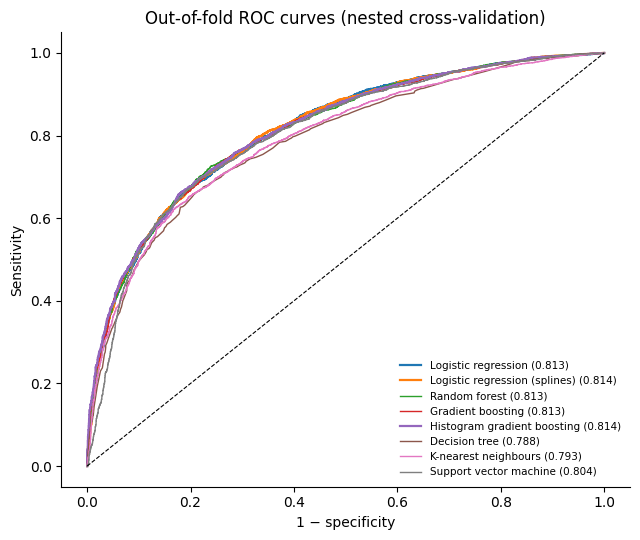

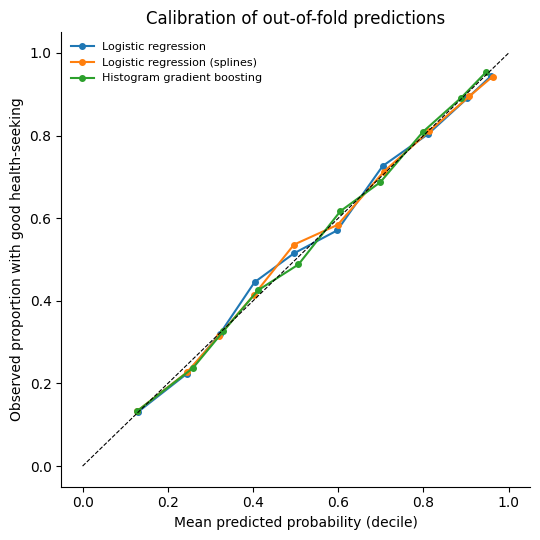

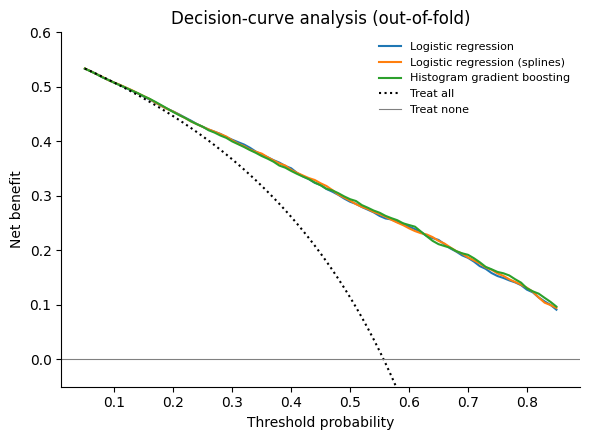

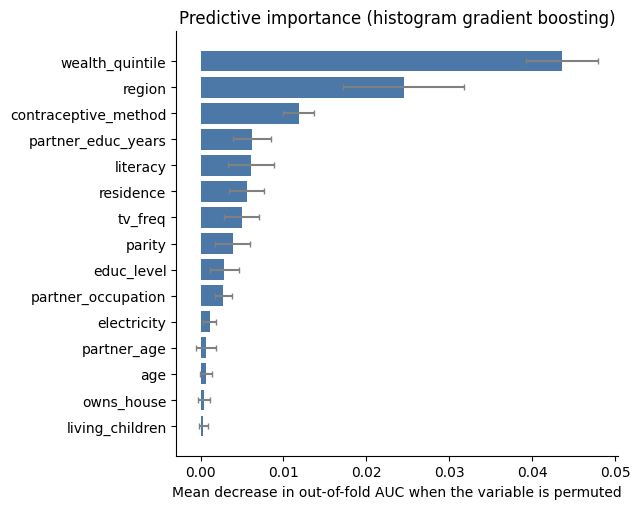


Table. Out-of-fold performance (AUC with cluster-bootstrap 95% CI, calibration, threshold metrics)


,AUC,AUC_lo,AUC_hi,fold_mean,fold_sd,wAUC,Brier,cal_slope,cal_int,sens@default,spec@default,ppv@default,npv@default,bal_acc@default,acc@default,f1@default
Model,,,,,,,,,,,,,,,,
Logistic regression,0.813,0.799,0.829,0.814,0.024,0.807,0.175,0.966,-0.000,0.751,0.709,0.764,0.694,0.730,0.732,0.758
Logistic regression (splines),0.814,0.799,0.829,0.814,0.023,0.807,0.175,0.953,-0.005,0.751,0.714,0.767,0.695,0.732,0.734,0.759
Random forest,0.813,0.798,0.828,0.813,0.022,0.802,0.176,1.140,-0.001,0.765,0.704,0.765,0.704,0.734,0.738,0.765
Gradient boosting,0.813,0.798,0.828,0.813,0.024,0.803,0.175,1.023,-0.005,0.763,0.707,0.766,0.704,0.735,0.739,0.765
Histogram gradient boosting,0.814,0.799,0.829,0.815,0.024,0.803,0.174,1.031,-0.003,0.766,0.701,0.763,0.704,0.733,0.737,0.764
Decision tree,0.788,0.774,0.803,0.788,0.020,0.774,0.186,0.790,0.001,0.728,0.705,0.756,0.674,0.717,0.718,0.742
K-nearest neighbours,0.793,0.778,0.809,0.793,0.024,0.786,0.186,1.015,0.206,0.669,0.781,0.794,0.652,0.725,0.719,0.726
Support vector machine,0.804,0.788,0.820,0.804,0.022,0.795,NaN,NaN,NaN,0.756,0.701,0.761,0.696,0.729,0.732,0.758



Table. Paired AUC differences vs logistic-regression references


,Model,Reference,diff,lo,hi,p_boot
0,Logistic regression,Logistic regression (splines),-0.000,-0.002,0.001,0.588
1,Logistic regression (splines),Logistic regression,0.000,-0.001,0.002,0.588
2,Random forest,Logistic regression,-0.000,-0.004,0.004,0.842
3,Random forest,Logistic regression (splines),-0.001,-0.005,0.003,0.688
4,Gradient boosting,Logistic regression,-0.001,-0.004,0.002,0.618
5,Gradient boosting,Logistic regression (splines),-0.001,-0.004,0.002,0.428
6,Histogram gradient boosting,Logistic regression,0.001,-0.002,0.004,0.536
7,Histogram gradient boosting,Logistic regression (splines),0.001,-0.003,0.004,0.732
8,Decision tree,Logistic regression,-0.025,-0.032,-0.018,0.001
9,Decision tree,Logistic regression (splines),-0.025,-0.032,-0.019,0.001



Table. Bootstrap CIs for Brier score, calibration slope and intercept


...

,Model,Metric,Value_at_0_5,lo,hi,Value_at_youden,youden_threshold
0,Logistic regression,sens,0.751,0.730,0.771,0.665,0.593
1,Logistic regression,spec,0.709,0.684,0.733,0.812,0.593
2,Logistic regression,ppv,0.764,0.746,0.784,0.816,0.593
3,Logistic regression,npv,0.694,0.667,0.718,0.659,0.593
4,Logistic regression,bal_acc,0.730,0.715,0.745,0.738,0.593
5,Logistic regression,acc,0.732,0.717,0.748,0.730,0.593
6,Logistic regression,f1,0.758,0.742,0.773,0.733,0.593
7,Logistic regression (splines),sens,0.751,0.729,0.771,0.693,0.563
8,Logistic regression (splines),spec,0.714,0.689,0.736,0.782,0.563
9,Logistic regression (splines),ppv,0.767,0.748,0.786,0.800,0.563



Table. Permutation importance, histogram gradient boosting (top 15)


,mean,sd
wealth_quintile,0.044,0.004
region,0.024,0.007
contraceptive_method,0.012,0.002
partner_educ_years,0.006,0.002
literacy,0.006,0.003
residence,0.006,0.002
tv_freq,0.005,0.002
parity,0.004,0.002
educ_level,0.003,0.002
partner_occupation,0.003,0.001



Table. Permutation importance, logistic regression with splines (top 15)


,mean,sd
wealth_quintile,0.030,0.002
region,0.026,0.009
contraceptive_method,0.013,0.004
residence,0.007,0.002
literacy,0.005,0.002
tv_freq,0.005,0.001
educ_level,0.004,0.002
partner_occupation,0.004,0.002
parity,0.003,0.002
age,0.003,0.002


In [6]:
import numpy as np, pandas as pd, pickle, warnings
warnings.filterwarnings('ignore')
import matplotlib; import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, confusion_matrix
from sklearn.linear_model import LogisticRegression
from scipy.optimize import brentq
R = pickle.load(open('main_results.pkl','rb'))
oof, y, groups, strata, wt = R['oof'], R['y'], R['groups'], R['strata'], R['wt']
models = list(oof); prob_models = [m for m in models if m != 'Support vector machine']
rng = np.random.default_rng(2026); B = 1000
# ---- stratified cluster bootstrap index sets (resample PSUs within strata) ----
df_ix = pd.DataFrame({'g':groups,'s':strata,'i':np.arange(len(y))})
psu_idx = {g: a.i.values for g, a in df_ix.groupby('g')}
strata_psus = {s: a.g.unique() for s, a in df_ix.groupby('s')}
def boot_index():
    ids = []
    for s, ps in strata_psus.items():
        pick = rng.choice(ps, size=len(ps), replace=True)
        ids.extend(psu_idx[g] for g in pick)
    return np.concatenate(ids)
boots = [boot_index() for _ in range(B)]
def logit(p): p = np.clip(p,1e-6,1-1e-6); return np.log(p/(1-p))
def cal(p, yy):
    lp = logit(p)
    slope = LogisticRegression(C=1e6, max_iter=500).fit(lp.reshape(-1,1), yy).coef_[0,0]
    f = lambda a: np.mean(1/(1+np.exp(-(lp+a)))) - yy.mean()
    try: a = brentq(f, -5, 5)
    except Exception: a = np.nan
    return slope, a
def tmetrics(p, yy, thr):
    pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(yy, pred, labels=[0,1]).ravel()
    sens = tp/(tp+fn); spec = tn/(tn+fp); ppv = tp/(tp+fp) if tp+fp else np.nan; npv = tn/(tn+fn) if tn+fn else np.nan
    return dict(sens=sens, spec=spec, ppv=ppv, npv=npv, bal_acc=(sens+spec)/2, acc=(tp+tn)/len(yy), f1=2*tp/(2*tp+fp+fn))
# ---- point estimates ----
rows = []; ci = {}
auc_b = {m: np.array([roc_auc_score(y[b], oof[m][b]) for b in boots]) for m in models}
for m in models:
    p = oof[m]; auc = roc_auc_score(y, p); lo, hi = np.percentile(auc_b[m], [2.5, 97.5])
    fa = np.array(R['fold_auc'][m])
    r = dict(Model=m, AUC=auc, AUC_lo=lo, AUC_hi=hi, fold_mean=fa.mean(), fold_sd=fa.std(ddof=1),
             wAUC=roc_auc_score(y, p, sample_weight=wt))
    if m in prob_models:
        r['Brier'] = brier_score_loss(y, p); sl, ic = cal(p, y); r['cal_slope'] = sl; r['cal_int'] = ic
        thr = 0.5
    else: thr = 0.0
    r.update({k+'@default': v for k, v in tmetrics(p, y, thr).items()})
    rows.append(r)
perf = pd.DataFrame(rows).set_index('Model'); perf.to_csv('perf_main.csv')
# Brier/calibration bootstrap CIs
cal_ci = {}
for m in prob_models:
    bs = []; sl = []; ic = []
    for b in boots[:500]:
        bs.append(brier_score_loss(y[b], oof[m][b])); s_, a_ = cal(oof[m][b], y[b]); sl.append(s_); ic.append(a_)
    cal_ci[m] = dict(Brier=np.percentile(bs,[2.5,97.5]), slope=np.percentile(sl,[2.5,97.5]), inter=np.nanpercentile(ic,[2.5,97.5]))
# threshold metrics with CIs for key models (default 0.5)
key = ['Logistic regression','Logistic regression (splines)','Histogram gradient boosting']
thr_rows = []
for m in key:
    pt = tmetrics(oof[m], y, 0.5)
    bt = pd.DataFrame([tmetrics(oof[m][b], y[b], 0.5) for b in boots[:500]])
    # Youden threshold from pooled OOF (data-driven; reported as exploratory)
    fpr, tpr, th = roc_curve(y, oof[m]); jt = th[np.argmax(tpr - fpr)]
    ptj = tmetrics(oof[m], y, jt)
    for k in pt:
        thr_rows.append(dict(Model=m, Metric=k, Value_at_0_5=pt[k], lo=bt[k].quantile(.025), hi=bt[k].quantile(.975), Value_at_youden=ptj[k], youden_threshold=jt))
pd.DataFrame(thr_rows).to_csv('thresholds.csv', index=False)
# ---- paired AUC differences ----
ref_list = ['Logistic regression','Logistic regression (splines)']
drows = []
for m in models:
    for ref in ref_list:
        if m == ref: continue
        dif = auc_b[m] - auc_b[ref]; est = perf.loc[m,'AUC'] - perf.loc[ref,'AUC']
        p = 2*min((dif <= 0).mean(), (dif >= 0).mean()); p = max(p, 1/B)
        drows.append(dict(Model=m, Reference=ref, diff=est, lo=np.percentile(dif,2.5), hi=np.percentile(dif,97.5), p_boot=p))
pd.DataFrame(drows).to_csv('auc_diffs.csv', index=False)
cipd = pd.DataFrame({k: {'Brier_lo':v['Brier'][0],'Brier_hi':v['Brier'][1],'slope_lo':v['slope'][0],'slope_hi':v['slope'][1],'int_lo':v['inter'][0],'int_hi':v['inter'][1]} for k,v in cal_ci.items()}).T
cipd.to_csv('cal_ci.csv')
# ---- figures ----
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig, ax = plt.subplots(figsize=(6.5,5.5))
for m in models:
    fpr, tpr, _ = roc_curve(y, oof[m]); ax.plot(fpr, tpr, lw=1.6 if m in key else 1, label=f"{m} ({perf.loc[m,'AUC']:.3f})")
ax.plot([0,1],[0,1],'k--',lw=.8); ax.set_xlabel('1 − specificity'); ax.set_ylabel('Sensitivity'); ax.legend(fontsize=7.5, loc='lower right', frameon=False)
ax.set_title('Out-of-fold ROC curves (nested cross-validation)'); plt.tight_layout(); plt.savefig('fig_roc.png', dpi=300); plt.show()
fig, ax = plt.subplots(figsize=(5.5,5.5))
for m in key:
    p = oof[m]; q = pd.qcut(p, 10, duplicates='drop'); g = pd.DataFrame({'p':p,'y':y,'q':q}).groupby('q', observed=True).mean()
    ax.plot(g.p, g.y, 'o-', ms=4, label=m)
ax.plot([0,1],[0,1],'k--',lw=.8); ax.set_xlabel('Mean predicted probability (decile)'); ax.set_ylabel('Observed proportion with good health-seeking'); ax.legend(frameon=False, fontsize=8)
ax.set_title('Calibration of out-of-fold predictions'); plt.tight_layout(); plt.savefig('fig_calibration.png', dpi=300); plt.show()
# decision curve
th = np.linspace(0.05, 0.85, 81); prev = y.mean()
fig, ax = plt.subplots(figsize=(6,4.5))
for m in key:
    nb = [ (np.sum((oof[m]>=t)&(y==1)) - np.sum((oof[m]>=t)&(y==0))*t/(1-t))/len(y) for t in th ]; ax.plot(th, nb, label=m)
ax.plot(th, [prev - (1-prev)*t/(1-t) for t in th], 'k:', label='Treat all'); ax.axhline(0, color='grey', lw=.8, label='Treat none')
ax.set_ylim(-0.05, 0.6); ax.set_xlabel('Threshold probability'); ax.set_ylabel('Net benefit'); ax.legend(frameon=False, fontsize=8); ax.set_title('Decision-curve analysis (out-of-fold)')
plt.tight_layout(); plt.savefig('fig_dca.png', dpi=300); plt.show()
# permutation importance (HGB) across outer folds
P = pd.concat(R['perm']['Histogram gradient boosting'], axis=1); imp = pd.DataFrame({'mean':P.mean(axis=1),'sd':P.std(axis=1,ddof=1)}).sort_values('mean', ascending=False)
imp.to_csv('perm_importance_hgb.csv')
P2 = pd.concat(R['perm']['Logistic regression (splines)'], axis=1); pd.DataFrame({'mean':P2.mean(axis=1),'sd':P2.std(axis=1,ddof=1)}).sort_values('mean',ascending=False).to_csv('perm_importance_lrspline.csv')
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(6.5,5.2)); ax.barh(top.index, top['mean'], xerr=top['sd'], color='#4C78A8', ecolor='grey', capsize=2)
ax.set_xlabel('Mean decrease in out-of-fold AUC when the variable is permuted'); ax.set_title('Predictive importance (histogram gradient boosting)')
plt.tight_layout(); plt.savefig('fig_perm_importance.png', dpi=300); plt.show()
pd.set_option('display.width',250); pd.set_option('display.max_columns',30)
imp_lr = pd.read_csv('perm_importance_lrspline.csv', index_col=0)
print('\nTable. Out-of-fold performance (AUC with cluster-bootstrap 95% CI, calibration, threshold metrics)'); display(perf)
print('\nTable. Paired AUC differences vs logistic-regression references'); display(pd.read_csv('auc_diffs.csv'))
print('\nTable. Bootstrap CIs for Brier score, calibration slope and intercept'); display(cipd)
print('\nTable. Threshold metrics (0.5 and Youden) with CIs'); display(pd.read_csv('thresholds.csv'))
print('\nTable. Permutation importance, histogram gradient boosting (top 15)'); display(imp.head(15))
print('\nTable. Permutation importance, logistic regression with splines (top 15)'); display(imp_lr.head(15))


## 5. Sensitivity analyses

In [7]:
import numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
d, X, y0, meta, flow, cols = prepare()
g = meta.psu.values
cv = StratifiedGroupKFold(5, shuffle=True, random_state=7)
def run(X_, y_, cols_, label):
    out = {'Definition / specification': label, 'Prevalence of "good"': f'{y_.mean()*100:.1f}%', 'N': len(y_)}
    for name, mk, spl in [('LR', lambda: LogisticRegression(C=1, max_iter=3000), False),
                          ('LR splines', lambda: LogisticRegression(C=0.1, max_iter=3000), True),
                          ('HGB', lambda: HistGradientBoostingClassifier(learning_rate=0.05, max_iter=150, max_leaf_nodes=15, random_state=7), False)]:
        pipe = Pipeline([('pre', make_pre(cols_, spline=spl)), ('m', mk())])
        p = cross_val_predict(pipe, X_, y_, groups=g, cv=cv, method='predict_proba')[:, 1]
        out['AUC ' + name] = round(roc_auc_score(y_, p), 3)
    return out
res = []
res.append(run(X, y0, cols, 'Primary: ≥2 of 4 components'))
comp = d[['c_anc4','c_facility','c_early_anc','c_tt2']]
res.append(run(X, ((comp[['c_anc4','c_facility','c_early_anc']].sum(axis=1)) >= 2).astype(int).values, cols, 'Omit tetanus component: ≥2 of 3'))
res.append(run(X, ((d.c_anc4 + d.c_facility) == 2).astype(int).values, cols, 'ANC 4+ visits AND facility delivery'))
res.append(run(X, (d.score >= 3).astype(int).values, cols, 'Stricter threshold: ≥3 of 4'))
anc8 = (d.m14 >= 8).astype(float)
res.append(run(X, ((anc8 + d.c_facility + d.c_early_anc + d.c_tt2) >= 2).astype(int).values, cols, 'WHO-2016 contacts: ANC 8+ replaces 4+'))
res.append(run(X, d.c_facility.astype(int).values, cols, 'Single component: facility delivery'))
res.append(run(X, d.c_anc4.astype(int).values, cols, 'Single component: ANC 4+ visits'))
# predictor-set sensitivity
cols2 = {k: [c for c in v if c not in ('contraceptive_method','currently_pregnant')] for k, v in cols.items()}
X2 = X.drop(columns=['contraceptive_method','currently_pregnant'])
res.append(run(X2, y0, cols2, 'Primary outcome; contraceptive method and pregnancy status removed'))
cols3 = {k: [c for c in v if c not in ('partner_age','partner_educ_years','partner_educ_level','partner_occupation','partner_educ_highest','decide_own_health','decide_purchases')] for k, v in cols.items()}
X3 = X[[c for c in X.columns if c in sum(cols3.values(), [])]]
res.append(run(X3, y0, cols3, 'Primary outcome; partner and decision-making variables removed'))
# sampling weight as a predictor (original practice) for comparison only
X4 = X.copy(); X4['sampling_weight'] = meta.wt.values; cols4 = {k: list(v) for k, v in cols.items()}; cols4['cont'] = cols4['cont'] + ['sampling_weight']
res.append(run(X4, y0, cols4, 'For comparison only: sampling weight added as predictor'))
out = pd.DataFrame(res); out.to_csv('sensitivity.csv', index=False)
pd.set_option('display.width',250); pd.set_option('display.max_columns',20)
print('\nTable. Sensitivity analyses (pooled out-of-fold AUC)'); display(out)


Table. Sensitivity analyses (pooled out-of-fold AUC)


,Definition / specification,"Prevalence of ""good""",N,AUC LR,AUC LR splines,AUC HGB
0,Primary: ≥2 of 4 components,55.7%,6658,0.814,0.814,0.814
1,Omit tetanus component: ≥2 of 3,44.6%,6658,0.820,0.820,0.819
2,ANC 4+ visits AND facility delivery,37.3%,6658,0.842,0.843,0.842
3,Stricter threshold: ≥3 of 4,35.4%,6658,0.799,0.800,0.800
4,WHO-2016 contacts: ANC 8+ replaces 4+,46.8%,6658,0.787,0.789,0.792
5,Single component: facility delivery,56.5%,6658,0.847,0.848,0.851
6,Single component: ANC 4+ visits,46.9%,6658,0.789,0.789,0.790
7,Primary outcome; contraceptive method and preg...,55.7%,6658,0.809,0.809,0.811
8,Primary outcome; partner and decision-making v...,55.7%,6658,0.814,0.813,0.811
9,For comparison only: sampling weight added as ...,55.7%,6658,0.814,0.814,0.813


## 6. Partial-dependence comparison

{'learning_rate': 0.03, 'max_iter': 200, 'max_leaf_nodes': 8} {'C': 0.1} {'C': 0.1}


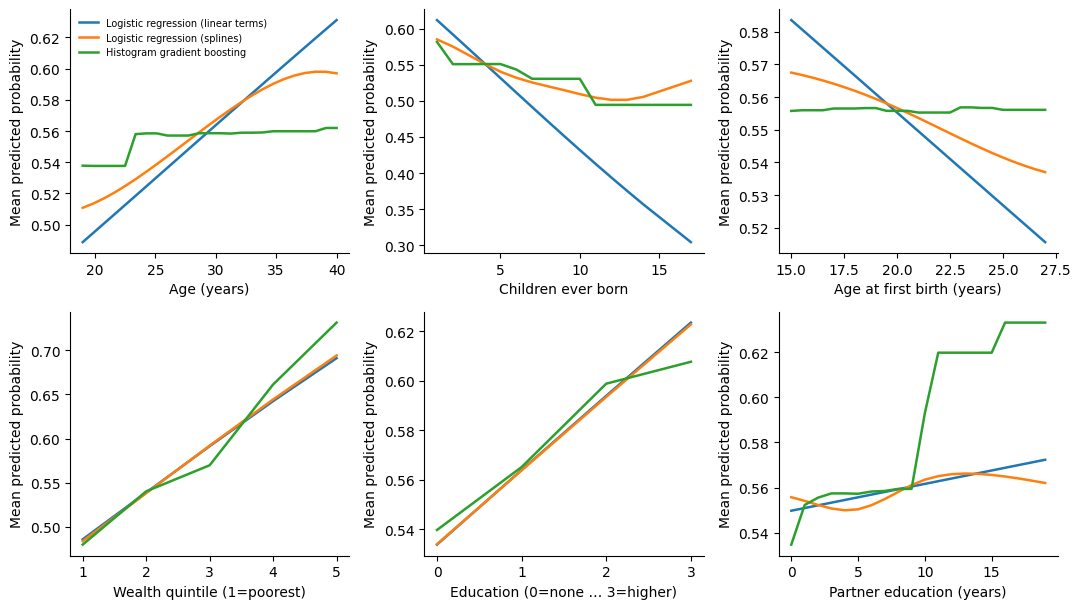


Table. Partial-dependence values


model,feature,x,Histogram gradient boosting,Logistic regression (linear terms),Logistic regression (splines)
0,age,19.000,0.538,0.489,0.511
1,age,19.875,0.538,0.495,0.514
2,age,20.750,0.538,0.501,0.517
3,age,21.625,0.538,0.507,0.521
4,age,22.500,0.538,0.513,0.525
5,age,23.375,0.558,0.519,0.529
6,age,24.250,0.559,0.524,0.534
7,age,25.125,0.559,0.530,0.539
8,age,26.000,0.557,0.536,0.544
9,age,26.875,0.557,0.542,0.549


In [8]:
import numpy as np, pandas as pd, pickle, warnings
warnings.filterwarnings('ignore')
import matplotlib; import matplotlib.pyplot as plt
from collections import Counter
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import partial_dependence
R = pickle.load(open('main_results.pkl','rb'))
d, X, y, meta, flow, cols = prepare()
X = X.astype({c: float for c in cols['cont'] + cols['ord']})
def modal(m):
    c = Counter(tuple(sorted(p.items())) for p in R['best_params'][m]); return dict(c.most_common(1)[0][0])
ph = {k.replace('m__',''): v for k, v in modal('Histogram gradient boosting').items()}
pl = {k.replace('m__',''): v for k, v in modal('Logistic regression (splines)').items()}
pn = {k.replace('m__',''): v for k, v in modal('Logistic regression').items()}
print(ph, pl, pn)
fits = {
 'Logistic regression (linear terms)': Pipeline([('pre', make_pre(cols)), ('m', LogisticRegression(max_iter=3000, **pn))]).fit(X, y),
 'Logistic regression (splines)': Pipeline([('pre', make_pre(cols, spline=True)), ('m', LogisticRegression(max_iter=3000, **pl))]).fit(X, y),
 'Histogram gradient boosting': Pipeline([('pre', make_pre(cols)), ('m', HistGradientBoostingClassifier(random_state=2026, **ph))]).fit(X, y)}
feats = [('age','Age (years)'),('parity','Children ever born'),('age_first_birth','Age at first birth (years)'),('wealth_quintile','Wealth quintile (1=poorest)'),('educ_level','Education (0=none … 3=higher)'),('partner_educ_years','Partner education (years)')]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2)); rows = []
for ax, (f, lab) in zip(axes.ravel(), feats):
    for name, est in fits.items():
        pdp = partial_dependence(est, X, [f], kind='average', grid_resolution=25, method='predict_proba' if False else 'auto', response_method='predict_proba')
        gx, av = pdp['grid_values'][0], pdp['average'][0]
        ax.plot(gx, av, label=name, lw=1.8)
        rows.append(pd.DataFrame({'feature': f, 'model': name, 'x': gx, 'pd': av}))
    ax.set_xlabel(lab); ax.set_ylabel('Mean predicted probability')
axes[0,0].legend(fontsize=7, frameon=False)
for ax in axes.ravel(): ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig_pdp.png', dpi=300); plt.show(); pd.concat(rows).to_csv('pdp_values.csv', index=False)
pdp_all = pd.concat(rows)
print('\nTable. Partial-dependence values'); display(pdp_all.pivot_table(index=['feature','x'], columns='model', values='pd').reset_index())

## 7. (Optional, untested) LightGBM, XGBoost and SHAP
SHAP describes model predictions, not causal effects.

In [9]:
!pip -q install shap lightgbm xgboost

\nTable. LightGBM / XGBoost pooled out-of-fold AUC


,Model,Pooled out-of-fold AUC
0,LightGBM,0.814
1,XGBoost,0.813


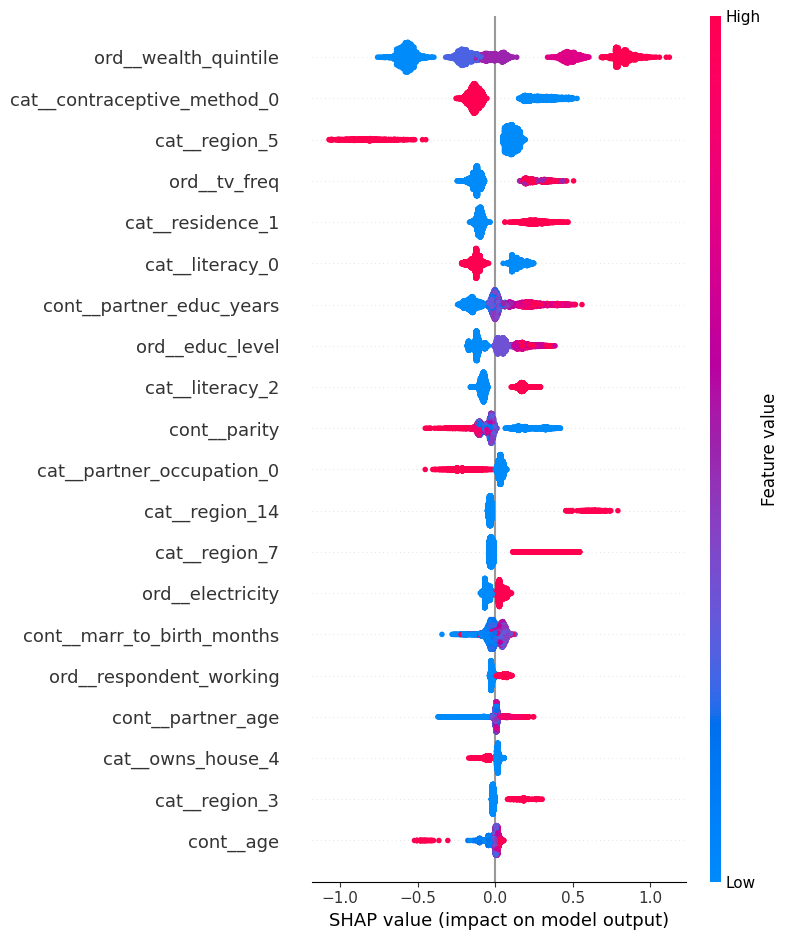

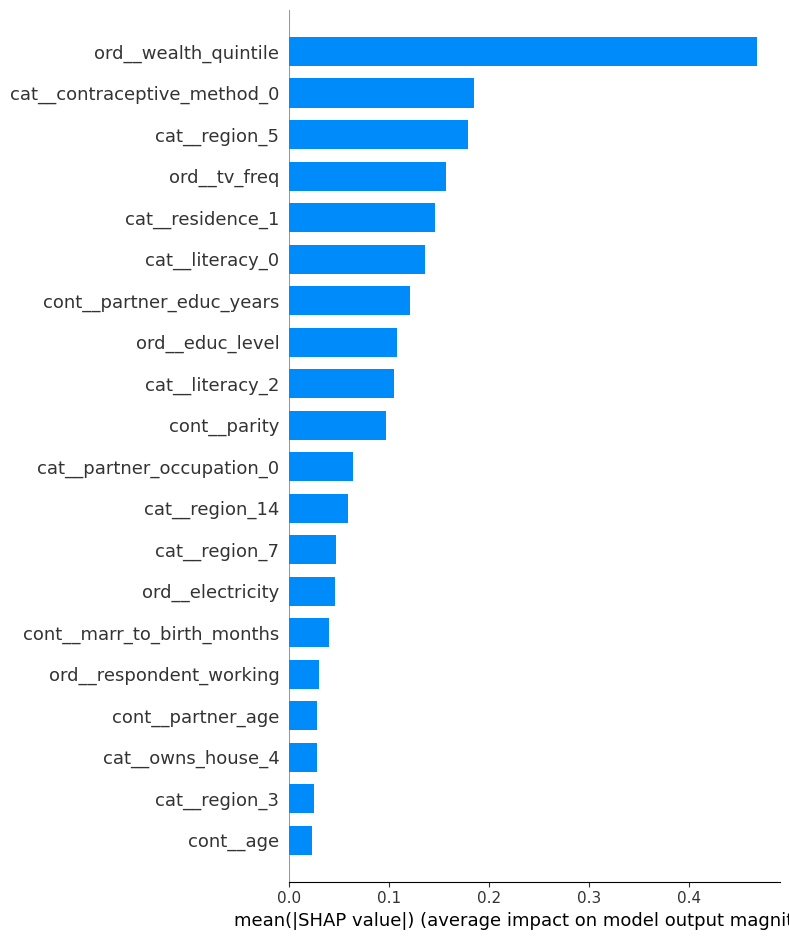

In [10]:
"""OPTIONAL add-on (run in an environment where lightgbm, xgboost and shap are installed, e.g. Colab).
NOT executed in the environment where the main results were produced - check the output before using it.
Adds LightGBM and XGBoost to the same nested, cluster-grouped cross-validation, and produces SHAP summaries
from a LightGBM model fitted to the full analytic sample (descriptive model explanation only, not causal)."""
import numpy as np, pandas as pd, pickle, warnings
warnings.filterwarnings('ignore')
import matplotlib; import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
import shap

d, X, y, meta, flow, cols = prepare(); groups = meta.psu.values; SEED = 2026
S = {'LightGBM': (lambda: LGBMClassifier(random_state=SEED, verbose=-1, n_jobs=1),
                  {'m__n_estimators': [100, 200], 'm__learning_rate': [0.03, 0.1], 'm__num_leaves': [8, 31]}),
     'XGBoost': (lambda: XGBClassifier(random_state=SEED, eval_metric='logloss', n_jobs=1),
                 {'m__n_estimators': [100, 200], 'm__learning_rate': [0.03, 0.1], 'm__max_depth': [2, 3]})}
outer = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)   # same outer folds as Section 3
oof = {k: np.zeros(len(y)) for k in S}
for f, (tr, te) in enumerate(outer.split(X, y, groups)):
    for name, (mk, grid) in S.items():
        inner = StratifiedGroupKFold(3, shuffle=True, random_state=SEED + f)
        gs = GridSearchCV(Pipeline([('pre', make_pre(cols)), ('m', mk())]), grid, cv=inner, scoring='roc_auc')
        gs.fit(X.iloc[tr], y[tr], groups=groups[tr]); oof[name][te] = gs.predict_proba(X.iloc[te])[:, 1]
auc_tab = pd.DataFrame({'Model': list(oof), 'Pooled out-of-fold AUC': [roc_auc_score(y, oof[k]) for k in oof]})
print('\\nTable. LightGBM / XGBoost pooled out-of-fold AUC'); display(auc_tab); auc_tab.to_csv('auc_lgbm_xgb.csv', index=False)
pickle.dump(oof, open('oof_lgbm_xgb.pkl', 'wb'))
# SHAP on a LightGBM model fitted to all data (descriptive; mean |SHAP| = magnitude of contribution, not direction or effect)
pre = make_pre(cols); Z = pre.fit_transform(X); names = pre.get_feature_names_out()
m = LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=8, random_state=SEED, verbose=-1).fit(Z, y)
sv = shap.TreeExplainer(m).shap_values(Z); sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, Z, feature_names=names, show=False, max_display=20); plt.tight_layout(); plt.savefig('fig_shap_beeswarm.png', dpi=300); plt.show()
shap.summary_plot(sv, Z, feature_names=names, plot_type='bar', show=False, max_display=20); plt.tight_layout(); plt.savefig('fig_shap_meanabs.png', dpi=300); plt.show()

## 8. Download outputs

In [11]:
import glob, zipfile
outs = sorted(glob.glob('*.csv') + glob.glob('fig_*.png') + ['main_results.pkl'])
with zipfile.ZipFile('results.zip', 'w') as z:
    for f in outs:
        if os.path.exists(f): z.write(f)
print('Saved to Google Drive:', OUT_DIR)
for f in outs: print(' -', f)
files.download('results.zip')


Saved to Google Drive: /content/drive/MyDrive/DHIS/results
 - auc_diffs.csv
 - auc_lgbm_xgb.csv
 - best_params.csv
 - cal_ci.csv
 - components.csv
 - excluded_compare.csv
 - fig_calibration.png
 - fig_dca.png
 - fig_pdp.png
 - fig_perm_importance.png
 - fig_roc.png
 - fig_shap_beeswarm.png
 - fig_shap_meanabs.png
 - fold_auc.csv
 - main_results.pkl
 - pdp_values.csv
 - perf_main.csv
 - perm_importance_hgb.csv
 - perm_importance_lrspline.csv
 - score_dist.csv
 - sensitivity.csv
 - table1.csv
 - table2.csv
 - table2b.csv
 - thresholds.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>